In [19]:
import pandas as pd

In [20]:
import numpy as np

In [21]:
import matplotlib.pyplot as plt

In [22]:
import seaborn as sns

In [24]:
df = pd.read_csv("C:/Users/ELCOT/Downloads/hotel_bookings.csv.zip")

In [25]:
df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [26]:
print(df.shape)

(119390, 32)


In [27]:
print(df.columns)

Index(['hotel', 'is_canceled', 'lead_time', 'arrival_date_year',
       'arrival_date_month', 'arrival_date_week_number',
       'arrival_date_day_of_month', 'stays_in_weekend_nights',
       'stays_in_week_nights', 'adults', 'children', 'babies', 'meal',
       'country', 'market_segment', 'distribution_channel',
       'is_repeated_guest', 'previous_cancellations',
       'previous_bookings_not_canceled', 'reserved_room_type',
       'assigned_room_type', 'booking_changes', 'deposit_type', 'agent',
       'company', 'days_in_waiting_list', 'customer_type', 'adr',
       'required_car_parking_spaces', 'total_of_special_requests',
       'reservation_status', 'reservation_status_date'],
      dtype='str')


In [28]:
print(df.dtypes)

hotel                                 str
is_canceled                         int64
lead_time                           int64
arrival_date_year                   int64
arrival_date_month                    str
arrival_date_week_number            int64
arrival_date_day_of_month           int64
stays_in_weekend_nights             int64
stays_in_week_nights                int64
adults                              int64
children                          float64
babies                              int64
meal                                  str
country                               str
market_segment                        str
distribution_channel                  str
is_repeated_guest                   int64
previous_cancellations              int64
previous_bookings_not_canceled      int64
reserved_room_type                    str
assigned_room_type                    str
booking_changes                     int64
deposit_type                          str
agent                             

In [29]:
print(df.isnull().sum())


hotel                                  0
is_canceled                            0
lead_time                              0
arrival_date_year                      0
arrival_date_month                     0
arrival_date_week_number               0
arrival_date_day_of_month              0
stays_in_weekend_nights                0
stays_in_week_nights                   0
adults                                 0
children                               4
babies                                 0
meal                                   0
country                              488
market_segment                         0
distribution_channel                   0
is_repeated_guest                      0
previous_cancellations                 0
previous_bookings_not_canceled         0
reserved_room_type                     0
assigned_room_type                     0
booking_changes                        0
deposit_type                           0
agent                              16340
company         

In [42]:
df['children'] = df['children'].fillna(df['children'].median())
df['agent'] = df['agent'].fillna(0)
df['company'] = df['company'].fillna(0)
df['country'] = df['country'].fillna('Unknown')


In [44]:
df = pd.get_dummies(
    df,
    columns=['reservation_status', 'reservation_status_date', 'total_of_special_req'],
    dtype=int
)
print(df.head())


KeyError: "None of [Index(['hotel', 'meal', 'market_segment'], dtype='str')] are in the [columns]"

In [36]:
print(df.isnull().sum())

is_canceled                       0
lead_time                         0
arrival_date_year                 0
arrival_date_month                0
arrival_date_week_number          0
arrival_date_day_of_month         0
stays_in_weekend_nights           0
stays_in_week_nights              0
adults                            0
children                          0
babies                            0
country                           0
distribution_channel              0
is_repeated_guest                 0
previous_cancellations            0
previous_bookings_not_canceled    0
reserved_room_type                0
assigned_room_type                0
booking_changes                   0
deposit_type                      0
agent                             0
company                           0
days_in_waiting_list              0
customer_type                     0
adr                               0
required_car_parking_spaces       0
total_of_special_requests         0
reservation_status          

In [37]:
columns = ['lead_time', 'adr', 'adults',
           'children', 'stays_in_week_nights']


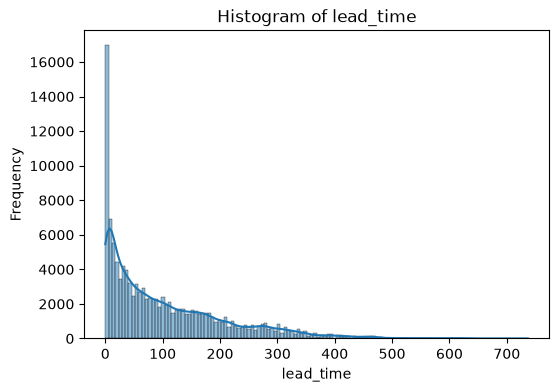

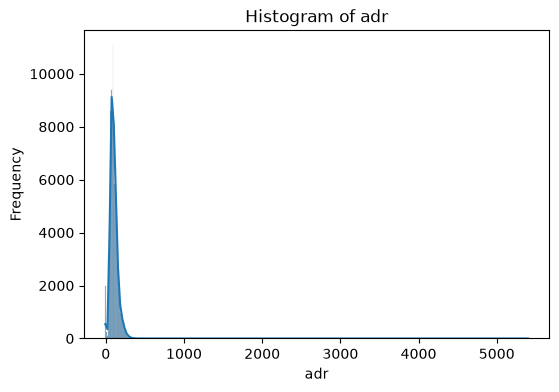

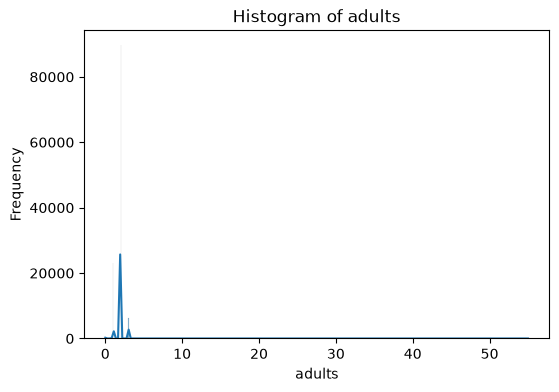

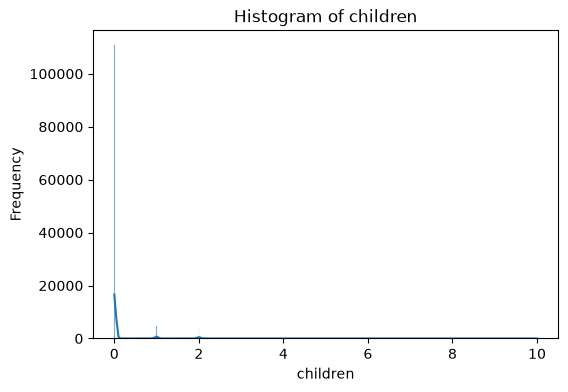

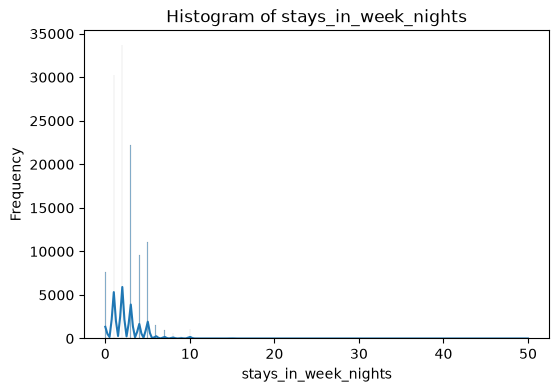

In [38]:
for col in columns:
    plt.figure(figsize=(6, 4))
    sns.histplot(df[col], kde=True)
    plt.title("Histogram of " + col)
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.show()

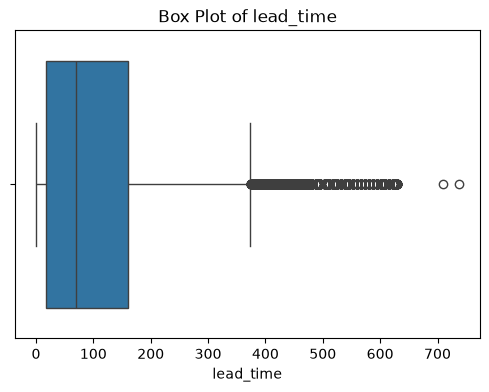

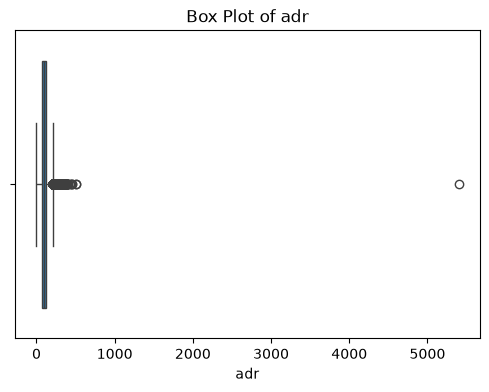

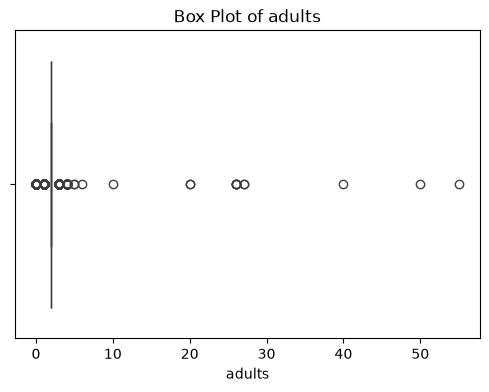

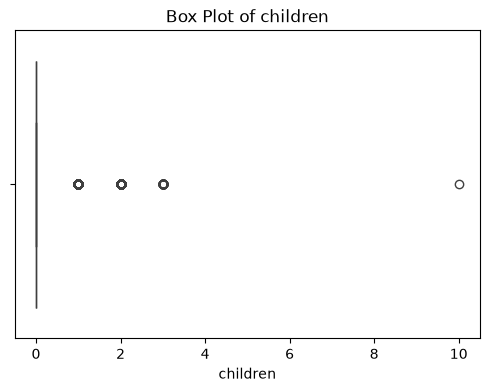

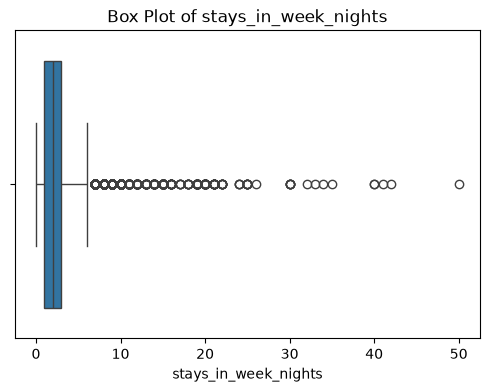

In [39]:
for col in columns:
    plt.figure(figsize=(6, 4))
    sns.boxplot(x=df[col])
    plt.title("Box Plot of " + col)
    plt.xlabel(col)
    plt.show()

In [40]:
print("\nSkewness and Kurtosis:")



Skewness and Kurtosis:


In [41]:
for col in columns:
    skew = df[col].skew()1
    kurt = df[col].kurt()

    print("\nColumn:", col)
    print("Skewness:", round(skew, 2))
    print("Kurtosis:", round(kurt, 2))

    if abs(skew) < 0.5:
        print("Distribution: Approximately Symmetric")
    elif skew > 0:
        print("Distribution: Positively Skewed")
    else:
        print("Distribution: Negatively Skewed")



Column: lead_time
Skewness: 1.35
Kurtosis: 1.7
Distribution: Positively Skewed

Column: adr
Skewness: 10.53
Kurtosis: 1013.19
Distribution: Positively Skewed

Column: adults
Skewness: 18.32
Kurtosis: 1352.12
Distribution: Positively Skewed

Column: children
Skewness: 4.11
Kurtosis: 18.67
Distribution: Positively Skewed

Column: stays_in_week_nights
Skewness: 2.86
Kurtosis: 24.28
Distribution: Positively Skewed
